In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style(style="darkgrid")

In [4]:
path = "/content/drive/MyDrive/Colab Notebooks/datasets/titanic_train.csv"

In [5]:
df = pd.read_csv(path)

In [6]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
df.shape

(891, 12)

The dataset consists of 891 rows(observations) and 12 columns(features)

### check data type and missing values

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Univariate Analysis: Survived


In [10]:
df['Survived'].value_counts()

0    549
1    342
Name: Survived, dtype: int64

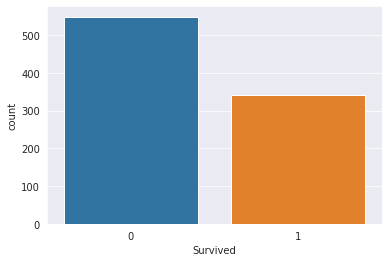

In [12]:
ax = sns.countplot(x='Survived',data=df)

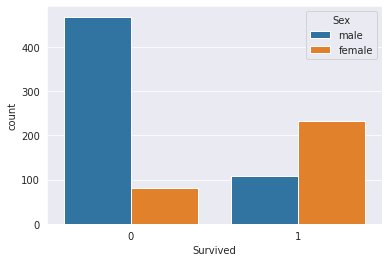

In [13]:
ax = sns.countplot(x='Survived',hue="Sex",data=df)

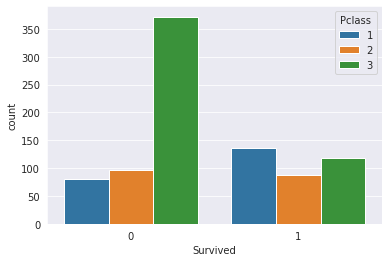

In [14]:
ax = sns.countplot(x='Survived',hue="Pclass",data=df)

Univariate Analysis: Pclass




In [15]:
df['Pclass'].value_counts()

3    491
1    216
2    184
Name: Pclass, dtype: int64

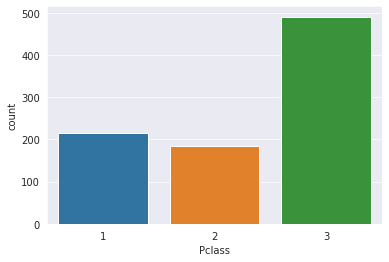

In [16]:
ax = sns.countplot(x='Pclass',data=df)

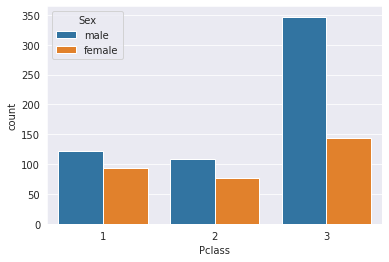

In [17]:
ax = sns.countplot(x='Pclass',hue='Sex',data=df)

Univariate Analysis: Sex

In [18]:
df['Sex'].value_counts()

male      577
female    314
Name: Sex, dtype: int64

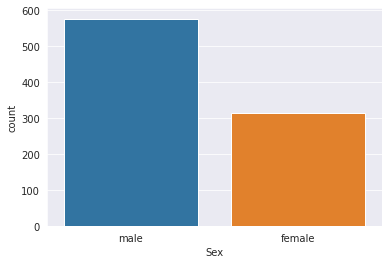

In [19]:
ax = sns.countplot(x='Sex',data=df)

Univariate analysis: Age

In [20]:
df['Age'].dtypes

dtype('float64')

In [21]:
df['Age'].isnull()

0      False
1      False
2      False
3      False
4      False
       ...  
886    False
887    False
888     True
889    False
890    False
Name: Age, Length: 891, dtype: bool

In [22]:
df['Age'].isnull().sum()

177

In [23]:
np.mean(df['Age'])

29.69911764705882

In [24]:
np.median(df['Age'])

nan

In [25]:
df['Age'].max()

80.0

In [26]:
df['Age'].min()

0.42

In [27]:
np.percentile(df['Age'].values,[25,50,75])

array([nan, nan, nan])

In [28]:
df['Age'].fillna(value=np.mean(df['Age']),inplace=True)

In [29]:
df['Age'].isnull().sum()

0

In [30]:
np.percentile(df['Age'].values,[25,50,75])

array([22.        , 29.69911765, 35.        ])

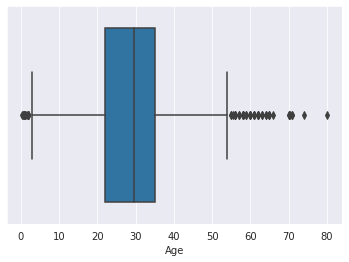

In [31]:
ax = sns.boxplot(x='Age',data=df)

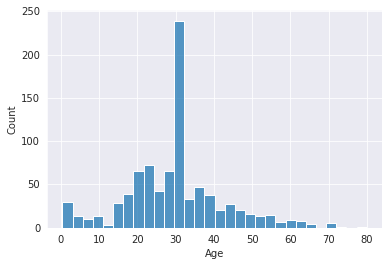

In [32]:
ax = sns.histplot(x='Age',data=df)

Univariate Analysis: Fare

In [33]:
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [34]:
df['Fare'].isnull().sum()

0

In [35]:
np.mean(df['Fare'])

32.2042079685746

In [36]:
np.median(df['Fare'])

14.4542

In [37]:
np.percentile(df['Fare'],[25,50,75])

array([ 7.9104, 14.4542, 31.    ])

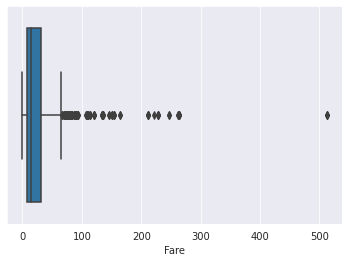

In [38]:
ax = sns.boxplot(x="Fare",data=df)

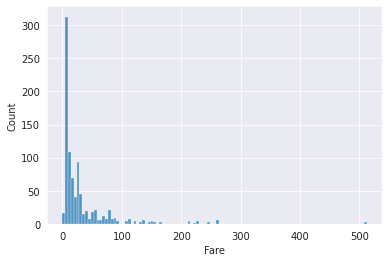

In [39]:
ax = sns.histplot(x="Fare",data=df)

Multivariate Analysis

In [40]:
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [41]:
df1 = df.groupby("Survived").mean()

In [42]:
df1

,PassengerId,Pclass,Age,SibSp,Parch,Fare
Survived,,,,,,
0,447.016393,2.531876,30.415100,0.553734,0.329690,22.117887
1,444.368421,1.950292,28.549778,0.473684,0.464912,48.395408


In [45]:
list(df1.index.values)

[0, 1]

In [46]:
list(df1['Age'].values)

[30.415099646415943, 28.549778121775027]